# Task 3 — Nhận dạng chuỗi 7 ký tự biển số

Từ ảnh biển số đã crop, dự đoán đủ **7 ký tự**, gồm ký tự tỉnh.

Đã khóa cấu hình bằng validation và đánh giá test độc lập. Task 3 hiện có **một seed fine-tune**, không trình bày thành ba lần train độc lập.

Notebook trình bày dữ liệu, kiến trúc và kết quả đã đo. `TRAIN=False` xem lại kết quả, không tự huấn luyện lại.

## Chuẩn bị

Dùng PyTorch cho model; pandas và matplotlib để xem dữ liệu. Các hàm đọc kết quả và vận hành được để trong helper như notebook M1.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd()/"src/utils.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT/"src"))
from notebook_support import (
    load_run, setup_plots, layer_shapes, load_weights, training_settings,
    validation_comparison, prepare_training, train_presented_model
)

setup_plots()
torch.set_num_threads(2)
TRAIN = False
TASK = "task3"
run = load_run(TASK, architecture="refined")
settings = run["config"]
torch.manual_seed(settings["seed"])

## 1. Đọc và kiểm tra dữ liệu

**CCPD-Base:** 50.000 ảnh trong cohort đã chọn, crop theo bounding box annotation. Đây là nhận dạng khi đã biết vị trí biển số; chưa đánh giá detector từ ảnh cả xe.

In [2]:
data = pd.read_csv(ROOT/"data/splits/ccpd_subset.csv")
# Vocabulary dùng cho model lấy từ thực nghiệm để giữ đúng thứ tự class.
from notebook_support import read_json, plate_examples, plate_batch
vocabulary = read_json(ROOT/"data/splits/ccpd_vocabulary.json")
display(data[["text", "split"]].head().rename(columns={"text": "Nhãn", "split": "Tập"}))
display(data.groupby("split").agg(Images=("text", "size"), Plates=("text", "nunique")))
print("Số class:", len(vocabulary))
print("Độ dài nhãn:", sorted(data.text.str.len().unique()))

,Nhãn,Tập
0,皖ADX640,train
1,皖AK9954,train
2,皖AF951F,validation
3,皖AE587T,train
4,皖ALX575,train


,Images,Plates
split,,
test,7482,6747
train,35043,31481
validation,7475,6746


Số class: 67
Độ dài nhãn: [np.int64(7)]


## 2. Xem ảnh và nhãn

Sáu ảnh đầu của train, không chọn thủ công ảnh đẹp. Giữ đủ ký tự tỉnh và sáu vị trí tiếp theo. Chia theo toàn chuỗi biển số để không trùng danh tính giữa các tập.

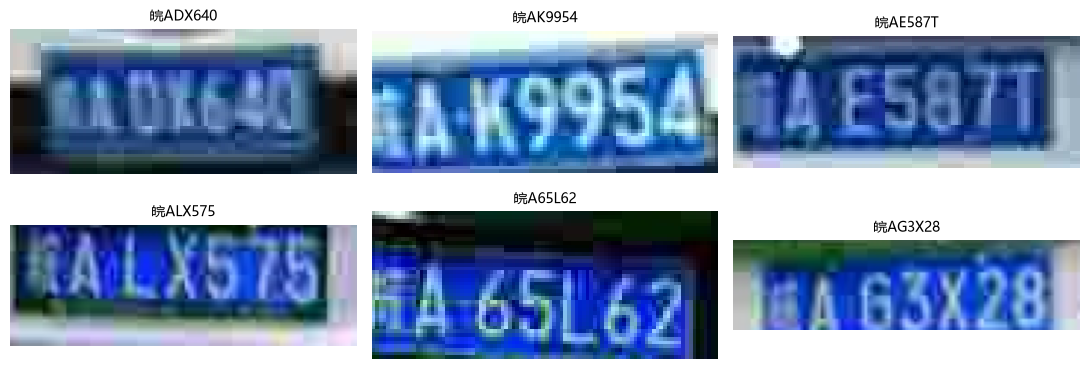

Plate trùng train/validation: 0
Plate trùng train/test: 0
Plate trùng validation/test: 0


,Ký tự tỉnh (train),Số ảnh,Tỷ lệ (%)
0,皖,33595,95.87
1,苏,598,1.71
2,浙,217,0.62
3,沪,120,0.34
4,粤,71,0.20


In [3]:
plate_examples(data)
groups = {split: set(data.loc[data.split.eq(split), "text"])
          for split in ["train", "validation", "test"]}
print("Plate trùng train/validation:", len(groups["train"] & groups["validation"]))
print("Plate trùng train/test:", len(groups["train"] & groups["test"]))
print("Plate trùng validation/test:", len(groups["validation"] & groups["test"]))
province_counts = data.loc[data.split.eq("train"), "text"].str[0].value_counts()
display(pd.DataFrame({"Ký tự tỉnh (train)": province_counts.index,
                      "Số ảnh": province_counts.values,
                      "Tỷ lệ (%)": 100*province_counts.values/province_counts.sum()}).head().round(2))

## 3. Tiền xử lý và tensor đầu vào

Crop → RGB → resize 192×64 → chia 255 → đổi sang `[B,3,64,192]`. Nhãn là chỉ số class `[B,7]`. Augmentation, nếu bật trong cấu hình, chỉ áp dụng train; validation và test giữ nguyên. Bảng thông số cho biết cấu hình thực tế.

In [4]:
X_example, y_example = plate_batch(data, vocabulary)
print("X:", tuple(X_example.shape), "range:", float(X_example.min()), "→", float(X_example.max()))
print("y:", tuple(y_example.shape))
display(pd.DataFrame({"Nhãn gốc": data[data.split.eq("train")].head(2).text.tolist(),
                      "Class IDs": y_example.tolist()}))

X: (2, 3, 64, 192) range: 0.0 → 1.0
y: (2, 7)


,Nhãn gốc,Class IDs
0,皖ADX640,"[0, 33, 36, 54, 63, 61, 57]"
1,皖AK9954,"[0, 33, 42, 66, 66, 62, 61]"


## 4. Xây dựng mô hình

`B` là batch size, `H` là hidden size. Dùng cùng dot-product attention: query so với các trạng thái đầu vào, softmax tạo trọng số, rồi lấy tổng có trọng số. Đây là một attention head, không phải MultiHeadAttention.

In [5]:
def dot_attention(query, memory):
    # query [B, outputs, H]; memory [B, input_positions, H].
    scores = torch.bmm(query, memory.transpose(1, 2)) / np.sqrt(memory.shape[-1])
    weights = scores.softmax(dim=-1)
    return torch.bmm(weights, memory), weights

**Luồng mới:** `[B,3,64,192]` → CNN `[B,128,8,48]` → học tổ hợp theo chiều cao `[B,48,128]` → pooling thành **7 vùng trái–phải** → trộn local region với global context → GRU decoder 7 bước → attention nhìn lại 48 cột → Linear → `[B,7,67]`.

Bản cũ lặp cùng context bảy lần và lấy trung bình theo chiều cao. Bản mới giữ được nét ở trên/dưới và cho mỗi bước decoder một vùng ảnh tương ứng. Khởi tạo từ CNN–GRU attention đã train trên **train**, rồi fine-tune; không phải train từ đầu.

**Hai phần bổ sung:** nhánh residual gồm hai Conv 3×3 hiệu chỉnh nét từ CNN; vector vị trí cho 48 cột giúp attention phân biệt trái/phải. Nhánh mới và vector vị trí bắt đầu bằng 0 để giữ nguyên dự đoán của checkpoint khởi tạo. Mô hình vẫn là CNN encoder → GRU decoder → attention, không dùng OCR ngoài.

**Chuỗi học thật:** checkpoint baseline attention → aligned → refined. Refined nạp trọng số aligned, không nạp trực tiếp baseline cũ. Mỗi giai đoạn có history riêng; learning curve bên dưới chỉ là giai đoạn refined.

In [6]:
class RefinedPlateSeq2Seq(nn.Module):
    def __init__(self, classes, config):
        super().__init__()
        h = config['hidden_size']
        self.attention = True
        self.alignment = config['alignment']
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, h, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d((2, 1))
        )
        self.refinement = nn.Sequential(
            nn.Conv2d(h, h, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(h, h, 3, padding=1)
        )
        # The new residual branch starts at zero, retaining the old features.
        nn.init.zeros_(self.refinement[-1].weight)
        nn.init.zeros_(self.refinement[-1].bias)
        self.height_projection = nn.Linear(8*h, h)
        with torch.no_grad():
            self.height_projection.weight.copy_(torch.eye(h).repeat(1, 8)/8)
            self.height_projection.bias.zero_()
        self.column_positions = nn.Parameter(torch.zeros(1, 48, h))
        self.character_regions = nn.AdaptiveAvgPool1d(7)
        self.decoder = nn.GRU(h, h, batch_first=True)
        self.output = nn.Linear(2*h, classes)

    def forward(self, X, return_attention=False):
        features = self.cnn(X)                         # [B, H, 8, 48]
        features = features + .1*self.refinement(features)
        columns = features.permute(0, 3, 2, 1).flatten(2)
        memory = self.height_projection(columns) + self.column_positions
        context = memory.mean(dim=1)                  # [B, H]
        regions = self.character_regions(memory.transpose(1, 2)).transpose(1, 2)
        decoder_input = (1-self.alignment)*context[:, None] + self.alignment*regions
        decoded, _ = self.decoder(decoder_input, context[None])
        attended, weights = dot_attention(decoded, memory)
        logits = self.output(torch.cat([decoded, attended], dim=-1))
        if return_attention:
            return logits, weights
        return logits

In [7]:
model = RefinedPlateSeq2Seq(len(vocabulary), settings)
if not TRAIN:
    load_weights(model, run)
layers, logits = layer_shapes(model, X_example)
print(model)
display(layers)
print("Logits:", tuple(logits.shape))
predicted_ids = logits.argmax(dim=-1)
display(pd.DataFrame({"Nhãn": data[data.split.eq("train")].head(2).text.tolist(),
                      "Dự đoán": ["".join(vocabulary[i] for i in row) for row in predicted_ids.tolist()]}))

RefinedPlateSeq2Seq(
  (cnn): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=(2, 1), stride=(2, 1), padding=0, dilation=1, ceil_mode=False)
  )
  (refinement): Sequential(
    (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (height_projection): Linear(in_features=1024, out_features=128, bias=True)
  (character_regions): AdaptiveAvgPool1d(output_size=7)
  (decoder): GRU(128, 128, batch_first=True)
  (output): Linear(in_features=256, out

,Layer,Input,Output,Parameters
0,cnn.0 (Conv2d),"(2, 3, 64, 192)","(2, 32, 64, 192)",896
1,cnn.1 (ReLU),"(2, 32, 64, 192)","(2, 32, 64, 192)",0
2,cnn.2 (MaxPool2d),"(2, 32, 64, 192)","(2, 32, 32, 96)",0
3,cnn.3 (Conv2d),"(2, 32, 32, 96)","(2, 64, 32, 96)",18496
4,cnn.4 (ReLU),"(2, 64, 32, 96)","(2, 64, 32, 96)",0
5,cnn.5 (MaxPool2d),"(2, 64, 32, 96)","(2, 64, 16, 48)",0
6,cnn.6 (Conv2d),"(2, 64, 16, 48)","(2, 128, 16, 48)",73856
7,cnn.7 (ReLU),"(2, 128, 16, 48)","(2, 128, 16, 48)",0
8,cnn.8 (MaxPool2d),"(2, 128, 16, 48)","(2, 128, 8, 48)",0
9,refinement.0 (Conv2d),"(2, 128, 8, 48)","(2, 128, 8, 48)",147584


Logits: (2, 7, 67)


,Nhãn,Dự đoán
0,皖ADX640,皖ADX640
1,皖AK9954,皖AK9954


Bảng trên là shape đi qua **layer thật** trên hai mẫu, không phải bảng shape viết tay. Attention, phép lấy trung bình và cộng residual là phép toán trong `forward`, nên cần đọc cùng sơ đồ và code phía trên.

## 5. Loss và huấn luyện

Thông số bên dưới thuộc run đã đo, không phải cấu hình recovery mới. Checkpoint được chọn bằng validation, không lấy epoch cuối một cách mặc định.

In [8]:
display(training_settings(run))

,Thông số,Giá trị
0,Seed,42.0
1,Hidden size,128.0
2,Batch run này,16.0
3,Learning rate ban đầu,0.0001
4,Epoch tối đa,24.0
5,Early-stopping patience,6.0
6,Epoch đã chạy,12.0
7,Epoch checkpoint tốt nhất,12.0
8,Thời gian train (giây),2498.18
9,Số tham số,642051.0


Model trả logits `[B,7,67]`; bước train transpose thành `[B,67,7]` cho cross-entropy, cùng target `[B,7]`. Không softmax trước loss; chỉ argmax khi dự đoán ký tự.

Hàm dưới đây là một bước cập nhật **được dùng trong vòng lặp train thật** của project. Ô này chỉ định nghĩa hàm, không tự train.

In [9]:
def plate_train_step(model, optimizer, X, y):
    optimizer.zero_grad(set_to_none=True)
    logits = model(X)                           # [B, 7, 67]
    loss = nn.functional.cross_entropy(logits.transpose(1, 2), y)
    if not torch.isfinite(loss):
        raise RuntimeError("Non-finite recognition training loss")
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.)
    optimizer.step()
    return loss.item()

Các lớp đã học dùng learning rate nhỏ; lớp mới dùng learning rate lớn hơn. Đây là cùng hàm tạo Adam được dùng trong script fine-tune.

In [10]:
def make_optimizer(model, config):
    groups = [
        {'params': model.cnn.parameters(), 'lr': config['cnn_learning_rate']},
        {'params': model.height_projection.parameters(), 'lr': config['projection_learning_rate']},
        {'params': list(model.decoder.parameters())+list(model.output.parameters()),
         'lr': config['learning_rate']}]
    if hasattr(model, 'refinement'):
        groups.append({'params':model.refinement.parameters(),'lr':config['refinement_learning_rate']})
        groups.append({'params':[model.column_positions],'lr':config['position_learning_rate']})
    return torch.optim.Adam(groups)

In [11]:
if TRAIN:
    model = prepare_training(model, settings["seed"])
optimizer = make_optimizer(model, settings)
display(pd.DataFrame({"Nhóm": range(1,len(optimizer.param_groups)+1),
                      "Learning rate": [group["lr"] for group in optimizer.param_groups],
                      "Số tham số": [sum(p.numel() for p in group["params"]) for group in optimizer.param_groups]}))

,Nhóm,Learning rate,Số tham số
0,1,0.00003,93248
1,2,0.00030,131200
2,3,0.00010,116291
3,4,0.00010,295168
4,5,0.00100,6144


Kết quả đã đo dùng chuỗi warm-start ở trên. Đổi `TRAIN=True` tạo trial mới từ đầu để học code; không tái tạo nguyên trạng benchmark fine-tune. Cách chạy chuỗi thực nghiệm được ghi trong README.

In [12]:
if TRAIN:
    run = train_presented_model(TASK, model, optimizer, settings, )
    display(training_settings(run))
history = run["history"]

history_columns = ['epoch', 'train_loss', 'val_loss', 'val_plate_accuracy', 'lr']
display(history[history_columns].tail(5).round(4))

,epoch,train_loss,val_loss,val_plate_accuracy,lr
7,8,0.0213,0.0817,0.9437,0.0001
8,9,0.0184,0.0860,0.9429,0.0001
9,10,0.0180,0.0854,0.9401,0.0001
10,11,0.0162,0.0943,0.9394,0.0001
11,12,0.0057,0.0733,0.9544,0.0000


## 6. Validation và lựa chọn cấu hình

So sánh ở seed 42 trước, chọn bằng validation. Chỉ cấu hình cuối mới được lặp thêm seed; không chọn seed theo điểm test. Learning curve dưới đây là run được phân tích ở trên.

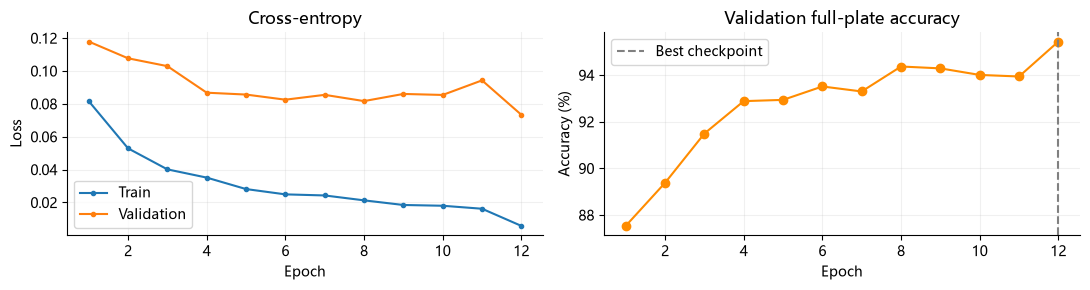

,Cấu hình,seed,Trạng thái,Full-plate (%),CER (%)
0,aligned_cnn_gru,42,Validation hoàn tất,80.348,3.574
1,cnn_gru,42,Validation hoàn tất,12.027,24.787
2,cnn_gru_attention,42,Validation hoàn tất,62.033,7.247
3,refined_spatial_cnn_gru,42,Validation hoàn tất,95.438,0.791
4,attention_position_finetune_reco...,42,Chưa hoàn tất validation,—,—


In [13]:
best_epoch = run["metadata"]["best_epoch"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(history.epoch, history.train_loss, marker="o", markersize=3, label="Train")
axes[0].set(xlabel="Epoch", ylabel="Loss")

axes[0].plot(history.epoch, history.val_loss, marker="o", markersize=3, label="Validation")
axes[0].set_title("Cross-entropy")
axes[1].plot(history.epoch, history.val_plate_accuracy * 100, marker="o", color="darkorange")
axes[1].set(title="Validation full-plate accuracy", xlabel="Epoch", ylabel="Accuracy (%)")

axes[0].legend()
axes[1].axvline(best_epoch, linestyle="--", color="grey", label="Best checkpoint")
axes[1].legend()
plt.tight_layout()
plt.show()
display(validation_comparison(TASK))

## 7. Benchmark test độc lập

Full-plate accuracy đo đúng **toàn bộ chuỗi**; character accuracy đo đúng từng vị trí; CER dùng edit distance / số ký tự thật. Không dùng character accuracy thay cho accuracy toàn biển. Các checkpoint đã khóa trước khi xem test; chỉ báo số seed thực sự có.

In [14]:
scores = run["scores"]
display(pd.DataFrame([{
    "Full-plate (%)": 100*scores["plate_accuracy"],
    "Character (%)": 100*scores["character_accuracy"],
    "CER (%)": 100*scores["CER"],
    "Ảnh đánh giá": len(run["predictions"]),
    "Seed": settings["seed"]
}]).round(3))
print(f"Biển số còn sai: {100*(1-scores['plate_accuracy']):.2f}%")
print("Mục tiêu trong plan: 90% full-plate —",
      "ĐẠT" if scores["plate_accuracy"] >= .90 else "CHƯA ĐẠT")

,Full-plate (%),Character (%),CER (%),Ảnh đánh giá,Seed
0,95.322,99.148,0.846,7482,42


Biển số còn sai: 4.68%
Mục tiêu trong plan: 90% full-plate — ĐẠT


So sánh trên **cùng tập test đã khóa**. Đây là các giai đoạn warm-start với thời lượng học khác nhau, không phải ablation tách biệt tác dụng từng layer.

In [15]:
from notebook_support import plate_test_comparison
test_comparison = plate_test_comparison()
display(test_comparison)

,Model,Seed,Full-plate (%),Character (%),CER (%),Parameters
0,cnn_gru_attention,42,62.764,92.743,7.236,209539
1,aligned_cnn_gru,42,80.540,96.353,3.637,340739
2,refined_spatial_cnn_gru,42,95.322,99.148,0.846,642051


Run baseline attention cũ có một file metric validation được phục hồi từ CSV đã đối chiếu manifest; các run mới tính metric từ dự đoán thực tế. Phụ lục PDF dùng decoded one-hot, không hồi quy trên mã số ký tự:

In [16]:
auxiliary = {key.removeprefix("aux_one_hot_"): value
             for key, value in scores.items() if key.startswith("aux_one_hot_")}
display(pd.DataFrame([auxiliary]).round(5))

,R2,NSE,MAE,RMSE
0,0.98271,0.98271,0.00025,0.01594


## 8. Phân tích lỗi

Ba biển đúng đầu tiên và ba biển sai đầu tiên trong tập đánh giá đang báo cáo. Mũi tên là nhãn thật → dự đoán; không dùng ảnh test để chọn lại model.

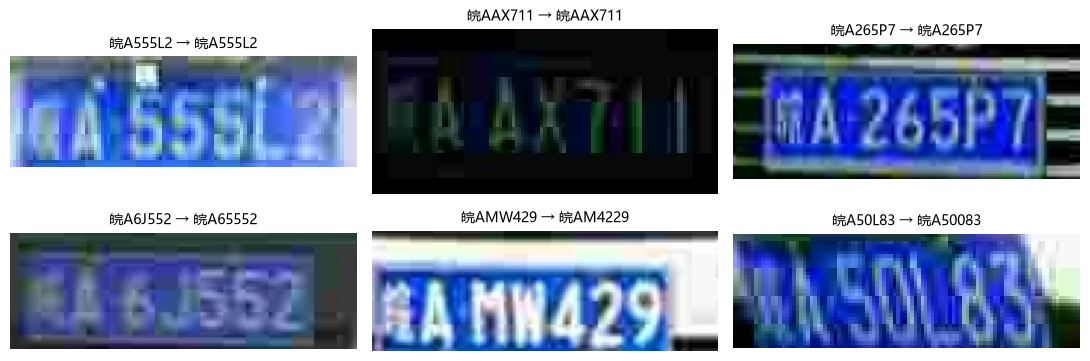

,Vị trí ký tự,Accuracy (%)
0,1,98.92
1,2,99.69
2,3,99.12
3,4,98.86
4,5,99.05
5,6,99.28
6,7,99.12


,Số ký tự chỉnh sửa,Số biển,Tỷ lệ (%)
0,0,7132,95.32
1,1,292,3.90
2,2,36,0.48
3,3,12,0.16
4,4,8,0.11
5,5,1,0.01
6,6,1,0.01


In [17]:
predictions = run["predictions"]
plate_examples(data, predictions)
position_accuracy = [np.mean([a[i] == b[i] for a, b in
                     zip(predictions.true_text, predictions.predicted_text)]) for i in range(7)]
display(pd.DataFrame({"Vị trí ký tự": range(1,8),
                      "Accuracy (%)": np.array(position_accuracy)*100}).round(2))
errors = predictions.edit_distance.value_counts().sort_index()
display(pd.DataFrame({"Số ký tự chỉnh sửa": errors.index,
                      "Số biển": errors.values,
                      "Tỷ lệ (%)": 100*errors.values/len(predictions)}).round(2))

Attention cho biết decoder đang chú ý cột nào. Bản đồ sáng không tự chứng minh dự đoán đúng; cần đọc cùng ảnh và nhãn. Vị trí tỉnh/thành ít đa dạng có thể làm character accuracy trông cao, trong khi nhiều biển vẫn sai ở các ký tự khác.

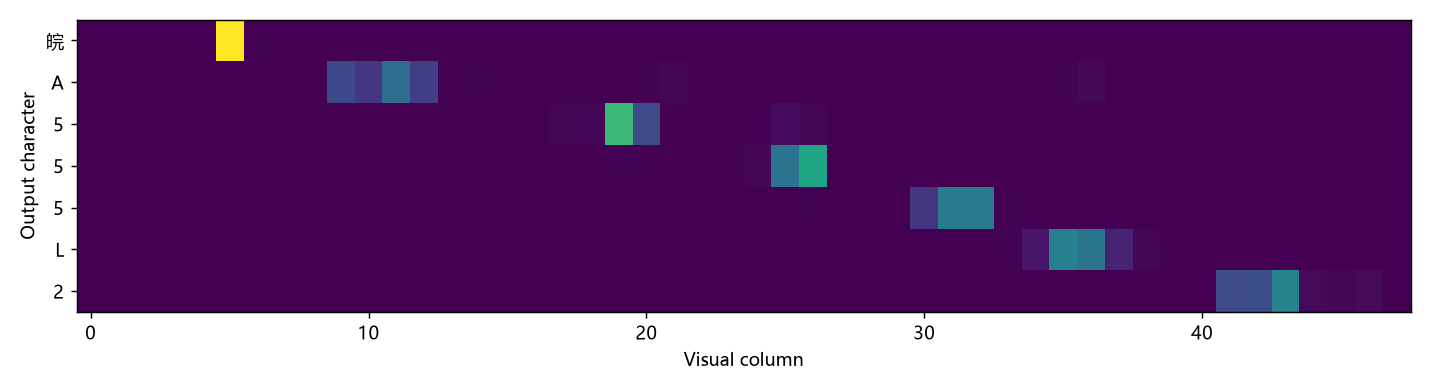

In [18]:
from IPython.display import Image
attention_figure = run["_folder"]/(run["split"]+"_attention.png")
if attention_figure.exists():
    display(Image(filename=str(attention_figure)))

## 9. Kết luận

Trên **7.482 ảnh test**, model cuối đạt **95.32% đúng toàn biển**, **99.15% đúng ký tự**, CER **0.85%**. So với baseline attention trên cùng test, tăng **32.56 điểm phần trăm**. Đạt mục tiêu 90% của plan ban đầu.

Cấu hình được chọn bằng validation trước khi mở test. Cải thiện là tổ hợp kiến trúc và fine-tuning, không khẳng định tác dụng riêng từng thành phần. Model cuối có **một seed fine-tune**, không có std qua ba seed để báo cáo.

**Giới hạn:** biển cố định 7 ký tự, crop từ annotation, dữ liệu/split riêng. Ảnh mờ, nghiêng và ký tự giống nhau vẫn có lỗi; chưa đánh giá detector hoặc biển có độ dài khác. Không so trực tiếp con số này với bài báo dùng cohort/split khác.

### Nguồn

[CCPD — repository của tác giả](https://github.com/detectRecog/CCPD). Cohort 50.000 ảnh, nguồn mirror cố định và cách chia theo chuỗi được ghi tại [data/raw/README.md](../data/raw/README.md).